# Data Preparation

Loads the UCI **RealWaste** dataset (9 classes), downscales every image to **64x64** (emulating a low-resource edge sensor), normalizes pixels to **[0, 1]**, and produces a fixed, stratified **70/15/15** train/val/test split with `RANDOM_SEED = 42`.

All of this logic lives in `data_loader.py` so downstream notebooks can just call `load_datasets()` / `get_dataloaders()` instead of repeating the preprocessing.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from data_loader import (
    CLASS_NAMES, NUM_CLASSES, IMG_SIZE, RANDOM_SEED,
    load_datasets, get_dataloaders,
)

print(f"RANDOM_SEED = {RANDOM_SEED}")
print(f"classes ({NUM_CLASSES}): {CLASS_NAMES}")

RANDOM_SEED = 42
classes (9): ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']


In [2]:
X_train, y_train, X_val, y_val, X_test, y_test = load_datasets()
total = len(y_train) + len(y_val) + len(y_test)

print(f"image shape: {X_train.shape[1:]}, dtype: {X_train.dtype}, range: [{X_train.min():.2f}, {X_train.max():.2f}]")
print(f"train: {len(y_train):4d} ({len(y_train) / total:.1%})")
print(f"val:   {len(y_val):4d} ({len(y_val) / total:.1%})")
print(f"test:  {len(y_test):4d} ({len(y_test) / total:.1%})")
print(f"total: {total}")

image shape: (64, 64, 3), dtype: float32, range: [0.00, 1.00]
train: 3327 (70.0%)
val:    712 (15.0%)
test:   713 (15.0%)
total: 4752


## Class balance across splits

The split is stratified per class (each class is independently divided 70/15/15), so class proportions stay consistent across train/val/test rather than a plain random shuffle that could starve small classes like *Textile Trash* from a split.

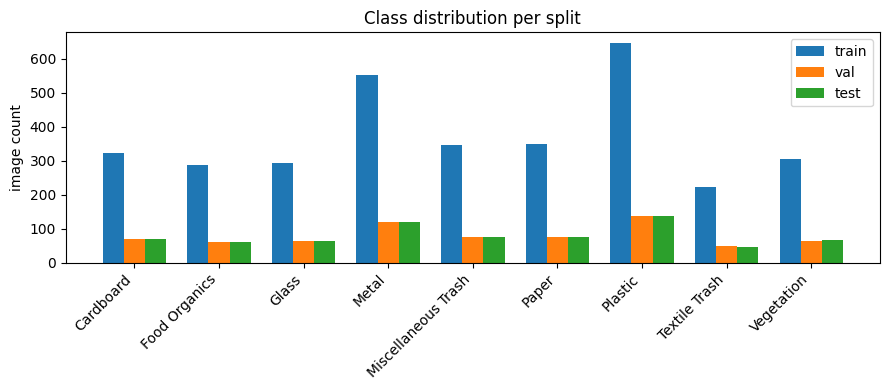

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(NUM_CLASSES)
width = 0.25

for offset, (name, y) in zip([-width, 0, width], [("train", y_train), ("val", y_val), ("test", y_test)]):
    counts = [np.sum(y == c) for c in range(NUM_CLASSES)]
    ax.bar(x + offset, counts, width=width, label=name)

ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
ax.set_ylabel("image count")
ax.set_title("Class distribution per split")
ax.legend()
plt.tight_layout()
plt.show()

## Sample images (post-preprocessing, 64x64, normalized)

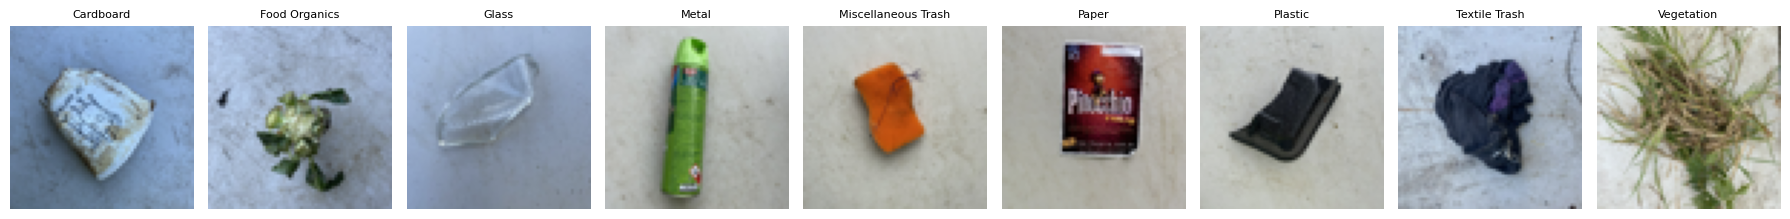

In [4]:
fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(18, 3))
for class_idx, ax in enumerate(axes):
    first_of_class = np.where(y_train == class_idx)[0][0]
    ax.imshow(X_train[first_of_class])
    ax.set_title(CLASS_NAMES[class_idx], fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

## DataLoaders for downstream notebooks

`get_dataloaders()` wraps the cached arrays in PyTorch `DataLoader`s (batched, CHW tensors) — this is what the downstream notebooks import directly.

In [5]:
train_loader, val_loader, test_loader = get_dataloaders(batch_size=32)
images, labels = next(iter(train_loader))
print(f"batch images: {images.shape} ({images.dtype})")  # (N, C, H, W)
print(f"batch labels: {labels.shape} ({labels.dtype})")

batch images: torch.Size([32, 3, 64, 64]) (torch.float32)
batch labels: torch.Size([32]) (torch.int64)
